In [1]:
print("Jupyter is working!")

Jupyter is working!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("data/train-test.csv")
validation_df = pd.read_csv("data/validation.csv")

print("Development data shape:", train_df.shape)
print("Validation data shape:", validation_df.shape)

Matplotlib is building the font cache; this may take a moment.


Development data shape: (48000, 14)
Validation data shape: (12000, 13)


In [3]:
print("Columns in development data:")
for i, column in enumerate(train_df.columns, 1):
    print(f"{i}. {column}")

Columns in development data:
1. load_id
2. pickup
3. delivery
4. pickup_lat
5. pickup_lon
6. delivery_lat
7. delivery_lon
8. distance
9. equipment
10. weight
11. date
12. market_index
13. quote_signal
14. posted_rate


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [5]:
validation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       12000 non-null  object 
 1   pickup        12000 non-null  object 
 2   delivery      12000 non-null  object 
 3   pickup_lat    12000 non-null  float64
 4   pickup_lon    12000 non-null  float64
 5   delivery_lat  12000 non-null  float64
 6   delivery_lon  12000 non-null  float64
 7   distance      12000 non-null  float64
 8   equipment     12000 non-null  object 
 9   weight        11835 non-null  float64
 10  date          12000 non-null  object 
 11  market_index  11751 non-null  float64
 12  quote_signal  12000 non-null  float64
dtypes: float64(8), object(5)
memory usage: 1.2+ MB


In [6]:
missing = train_df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values:")
print(missing)


Missing values:
market_index    374
weight          300
dtype: int64


In [7]:
missing_validation = validation_df.isnull().sum()

missing_validation = missing_validation[missing_validation > 0].sort_values(ascending=False)

print("Missing values in validation:")
print(missing_validation)

Missing values in validation:
market_index    249
weight          165
dtype: int64


In [8]:
print("Duplicate rows in development data:", train_df.duplicated().sum())
print("Duplicate rows in validation data:", validation_df.duplicated().sum())

Duplicate rows in development data: 0
Duplicate rows in validation data: 0


In [9]:
train_df["posted_rate"].describe()

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

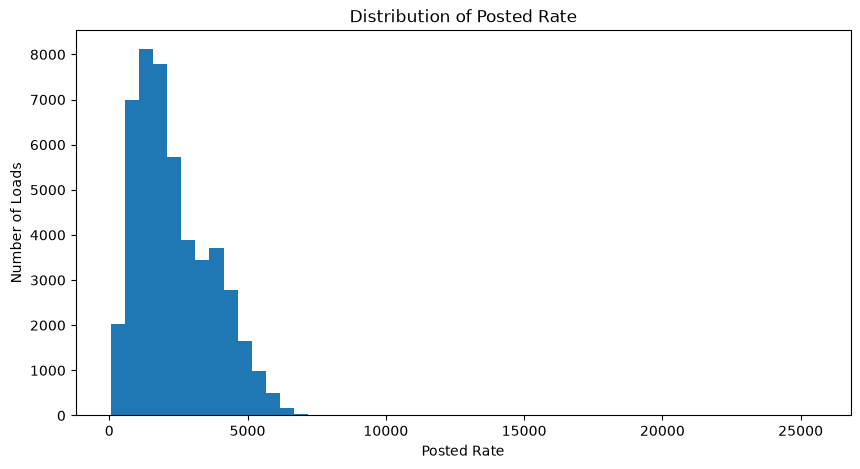

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(train_df["posted_rate"], bins=50)

plt.xlabel("Posted Rate")
plt.ylabel("Number of Loads")
plt.title("Distribution of Posted Rate")

plt.show()

In [11]:
train_df.columns.tolist()

['load_id',
 'pickup',
 'delivery',
 'pickup_lat',
 'pickup_lon',
 'delivery_lat',
 'delivery_lon',
 'distance',
 'equipment',
 'weight',
 'date',
 'market_index',
 'quote_signal',
 'posted_rate']

In [12]:
train_df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [13]:
print("Equipment:")
print(train_df["equipment"].value_counts())

print("\nPickup:")
print(train_df["pickup"].nunique(), "unique pickup values")

print("\nDelivery:")
print(train_df["delivery"].nunique(), "unique delivery values")

Equipment:
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

Pickup:
64 unique pickup values

Delivery:
64 unique delivery values


In [14]:
print("Minimum date:", train_df["date"].min())
print("Maximum date:", train_df["date"].max())

Minimum date: 2025-01-01
Maximum date: 2025-10-31


In [15]:
print(train_df["date"].head(10))

0    2025-01-01
1    2025-01-01
2    2025-01-01
3    2025-01-01
4    2025-01-01
5    2025-01-01
6    2025-01-01
7    2025-01-01
8    2025-01-01
9    2025-01-01
Name: date, dtype: object


In [16]:
train_df["posted_rate"].describe()

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

In [17]:
print(train_df["load_id"].head(10))
print("\nUnique load IDs:", train_df["load_id"].nunique())

0    TR-000001
1    TR-000002
2    TR-000003
3    TR-000004
4    TR-000005
5    TR-000006
6    TR-000007
7    TR-000008
8    TR-000009
9    TR-000010
Name: load_id, dtype: object

Unique load IDs: 48000


In [18]:
numeric_df = train_df.select_dtypes(include="number")

numeric_df.corr()["posted_rate"].sort_values(ascending=False)

posted_rate     1.000000
distance        0.908519
weight          0.034840
market_index    0.034165
quote_signal   -0.039858
pickup_lat     -0.090873
delivery_lat   -0.091970
pickup_lon     -0.255058
delivery_lon   -0.257086
Name: posted_rate, dtype: float64

In [19]:
numeric_columns = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

train_df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [20]:
for col in numeric_columns:
    print(f"\n--- {col} ---")
    print("Min:", train_df[col].min())
    print("Max:", train_df[col].max())
    print("Median:", train_df[col].median())


--- pickup_lat ---
Min: 28.35765
Max: 44.30296
Median: 35.29479

--- pickup_lon ---
Min: -121.69849
Max: -69.5
Median: -88.08915

--- delivery_lat ---
Min: 28.35765
Max: 44.30296
Median: 35.29479

--- delivery_lon ---
Min: -121.69849
Max: -69.5
Median: -87.52871

--- distance ---
Min: 70.0
Max: 3439.8
Median: 953.3

--- weight ---
Min: -47500.0
Max: 47500.0
Median: 31436.5

--- market_index ---
Min: 0.67639
Max: 1.46778
Median: 1.0558

--- quote_signal ---
Min: 0.69228
Max: 3.61035
Median: 2.05575

--- posted_rate ---
Min: 57.22
Max: 25533.0
Median: 2030.76


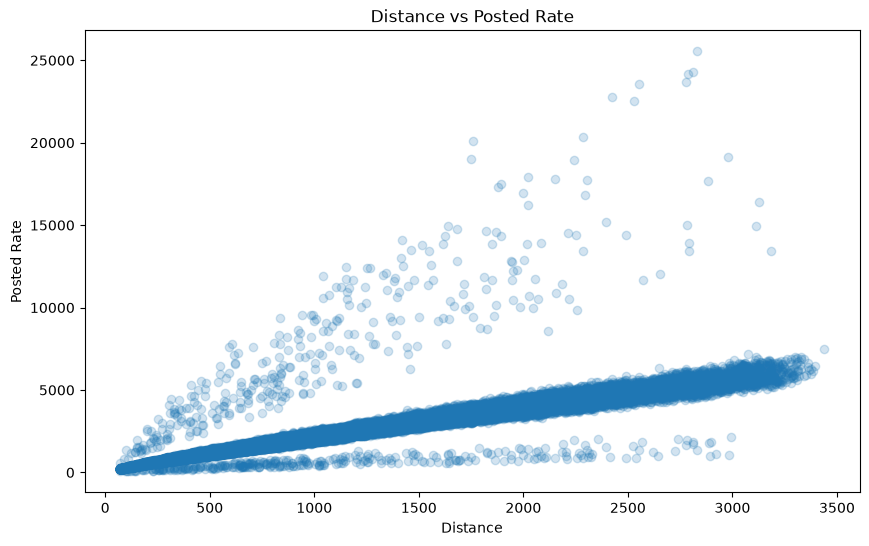

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    train_df["distance"],
    train_df["posted_rate"],
    alpha=0.2
)

plt.xlabel("Distance")
plt.ylabel("Posted Rate")
plt.title("Distance vs Posted Rate")

plt.show()

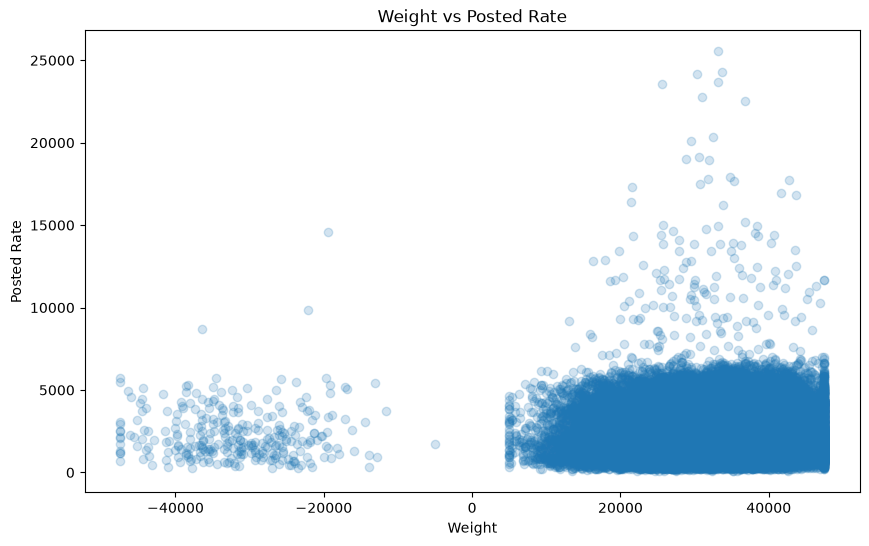

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    train_df["weight"],
    train_df["posted_rate"],
    alpha=0.2
)

plt.xlabel("Weight")
plt.ylabel("Posted Rate")
plt.title("Weight vs Posted Rate")

plt.show()

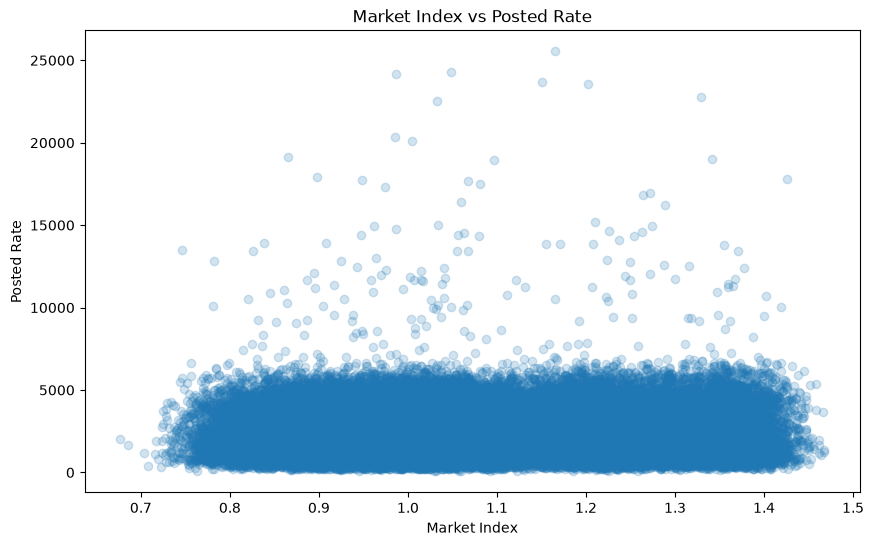

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(
    train_df["market_index"],
    train_df["posted_rate"],
    alpha=0.2
)

plt.xlabel("Market Index")
plt.ylabel("Posted Rate")
plt.title("Market Index vs Posted Rate")

plt.show()

In [24]:
equipment_summary = (
    train_df.groupby("equipment")["posted_rate"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

equipment_summary

,count,mean,median,min,max
equipment,,,,,
Reefer,12045,2553.636939,2196.670,63.36,24140.21
Flatbed,8753,2445.087223,2076.810,157.76,17893.17
Dry Van,27202,2271.548686,1953.035,57.22,25533.00


In [25]:
train_df["date"] = pd.to_datetime(train_df["date"])

In [26]:
print("Date range:")
print(train_df["date"].min())
print(train_df["date"].max())

Date range:
2025-01-01 00:00:00
2025-10-31 00:00:00


In [27]:
daily_rate = (
    train_df.groupby("date")["posted_rate"]
    .mean()
    .reset_index()
)

daily_rate.head()

,date,posted_rate
0,2025-01-01,2182.959586
1,2025-01-02,2223.485595
2,2025-01-03,2331.391154
3,2025-01-04,2334.728782
4,2025-01-05,2041.046688


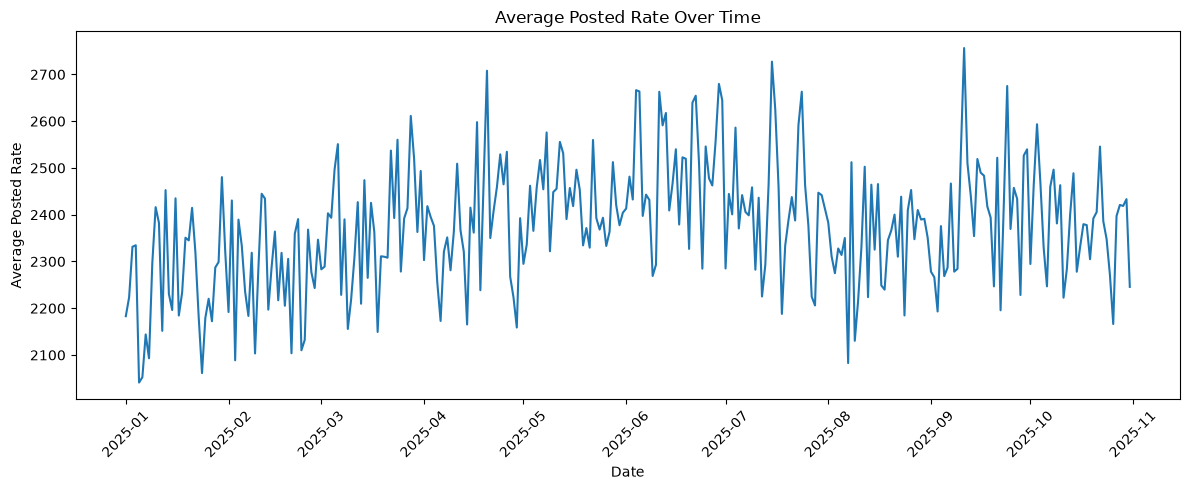

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_rate["date"],
    daily_rate["posted_rate"]
)

plt.xlabel("Date")
plt.ylabel("Average Posted Rate")
plt.title("Average Posted Rate Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
route_summary = (
    train_df.groupby(["pickup", "delivery"])
    .agg(
        loads=("posted_rate", "count"),
        avg_rate=("posted_rate", "mean"),
        median_rate=("posted_rate", "median")
    )
    .sort_values("loads", ascending=False)
)

route_summary.head(20)

loads     avg_rate  median_rate
pickup        delivery                                      
Columbia      Oklahoma City     39  2330.734615     2327.430
Phoenix       Shreveport        39  3507.618462     3554.430
Lexington     Atlanta           39   560.106154      553.630
Fort Wayne    Philadelphia      38  1681.032632     1708.835
Shreveport    Hartford          37  2867.768108     2812.520
Fort Wayne    Hartford          37  1938.657297     1725.990
Richmond      Oklahoma City     37  3093.435946     3126.490
              Phoenix           37  5190.194595     5010.880
Lexington     Kansas City       37  1042.474595     1029.800
              Cincinnati        37   396.691892      377.100
Fort Wayne    Cincinnati        36   871.521111      857.150
Mobile        Phoenix           36  4180.469167     3842.000
Richmond      Cincinnati        35  1472.597143     1445.430
Oklahoma City Nashville         35  1737.457143     1744.960
Hartford      Baton Rouge       35  3102.180571     3101.260
Oklahoma City Atlanta           35  1895.603714     1909.990
              Columbia          35  2333.602857     2279.320
Bakersfield   Hartford          35  5998.482286     5402.590
Oklahoma City Mobile            35  1517.043143     1644.700
Philadelphia  Lexington         35  1708.174857     1691.690

In [30]:
route_summary = (
    train_df.groupby(["pickup", "delivery"])
    .agg(
        loads=("posted_rate", "count"),
        avg_rate=("posted_rate", "mean"),
        median_rate=("posted_rate", "median")
    )
    .sort_values("loads", ascending=False)
)

route_summary.head(20)

loads     avg_rate  median_rate
pickup        delivery                                      
Columbia      Oklahoma City     39  2330.734615     2327.430
Phoenix       Shreveport        39  3507.618462     3554.430
Lexington     Atlanta           39   560.106154      553.630
Fort Wayne    Philadelphia      38  1681.032632     1708.835
Shreveport    Hartford          37  2867.768108     2812.520
Fort Wayne    Hartford          37  1938.657297     1725.990
Richmond      Oklahoma City     37  3093.435946     3126.490
              Phoenix           37  5190.194595     5010.880
Lexington     Kansas City       37  1042.474595     1029.800
              Cincinnati        37   396.691892      377.100
Fort Wayne    Cincinnati        36   871.521111      857.150
Mobile        Phoenix           36  4180.469167     3842.000
Richmond      Cincinnati        35  1472.597143     1445.430
Oklahoma City Nashville         35  1737.457143     1744.960
Hartford      Baton Rouge       35  3102.180571     3101.260
Oklahoma City Atlanta           35  1895.603714     1909.990
              Columbia          35  2333.602857     2279.320
Bakersfield   Hartford          35  5998.482286     5402.590
Oklahoma City Mobile            35  1517.043143     1644.700
Philadelphia  Lexington         35  1708.174857     1691.690

In [31]:
print("Target skewness:", train_df["posted_rate"].skew())

Target skewness: 1.9023948792201801


In [32]:
train_df["year"] = train_df["date"].dt.year
train_df["month"] = train_df["date"].dt.month
train_df["day"] = train_df["date"].dt.day
train_df["day_of_week"] = train_df["date"].dt.dayofweek

In [33]:
print(train_df[["date", "year", "month", "day", "day_of_week"]].head())

        date  year  month  day  day_of_week
0 2025-01-01  2025      1    1            2
1 2025-01-01  2025      1    1            2
2 2025-01-01  2025      1    1            2
3 2025-01-01  2025      1    1            2
4 2025-01-01  2025      1    1            2


In [34]:
train_df.groupby(["year", "month"]).size()

year  month
2025  1        4918
      2        4337
      3        5036
      4        4819
      5        4913
      6        4783
      7        4912
      8        4759
      9        4670
      10       4853
dtype: int64

In [35]:
monthly_rate = (
    train_df.groupby(["year", "month"])["posted_rate"]
    .agg(["count", "mean", "median"])
)

monthly_rate

count         mean    median
year month                              
2025 1       4918  2255.967048  1915.200
     2       4337  2273.804801  1994.250
     3       5036  2372.268092  2022.920
     4       4819  2372.162308  2044.240
     5       4913  2421.776342  2065.510
     6       4783  2497.030115  2120.220
     7       4912  2415.162030  2059.145
     8       4759  2338.407661  2015.730
     9       4670  2406.374013  2057.130
     10      4853  2379.051374  2035.900

In [36]:
weekday_rate = (
    train_df.groupby("day_of_week")["posted_rate"]
    .agg(["count", "mean", "median"])
)

weekday_rate

,count,mean,median
day_of_week,,,
0,6769,2349.308676,2015.110
1,6737,2372.890626,2029.630
2,7007,2405.086706,2036.580
3,6934,2403.265599,2037.650
4,6975,2376.849855,2029.100
5,6770,2373.714334,2044.845
6,6808,2335.073176,2022.035


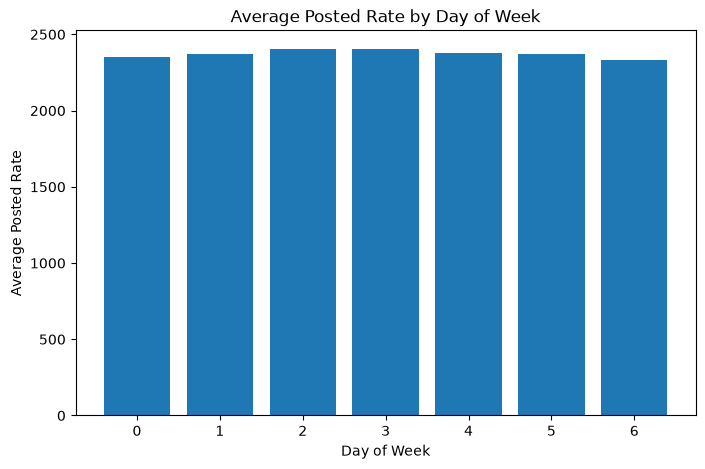

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    weekday_rate.index,
    weekday_rate["mean"]
)

plt.xlabel("Day of Week")
plt.ylabel("Average Posted Rate")
plt.title("Average Posted Rate by Day of Week")

plt.show()

In [38]:
train_df["route"] = (
    train_df["pickup"].astype(str)
    + " -> "
    + train_df["delivery"].astype(str)
)

In [39]:
print("Unique routes:", train_df["route"].nunique())

Unique routes: 4014


In [40]:
route_stats = (
    train_df.groupby("route")["posted_rate"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

route_stats.head(20)

,count,mean,median
route,,,
Columbia -> Oklahoma City,39,2330.734615,2327.430
Phoenix -> Shreveport,39,3507.618462,3554.430
Lexington -> Atlanta,39,560.106154,553.630
Fort Wayne -> Philadelphia,38,1681.032632,1708.835
Shreveport -> Hartford,37,2867.768108,2812.520
Fort Wayne -> Hartford,37,1938.657297,1725.990
Richmond -> Oklahoma City,37,3093.435946,3126.490
Richmond -> Phoenix,37,5190.194595,5010.880
Lexington -> Kansas City,37,1042.474595,1029.800


In [41]:
train_df["rate_per_distance"] = (
    train_df["posted_rate"] / train_df["distance"].replace(0, np.nan)
)

In [42]:
train_df["rate_per_distance"].describe()

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rate_per_distance, dtype: float64

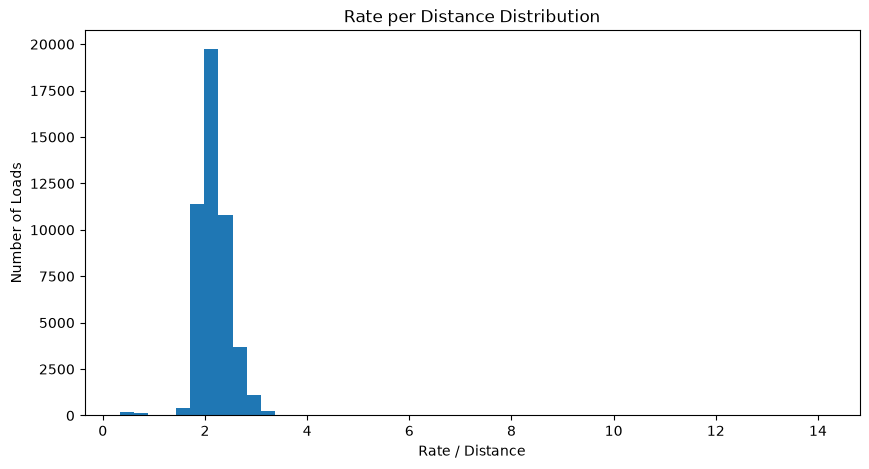

In [43]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_df["rate_per_distance"].dropna(),
    bins=50
)

plt.xlabel("Rate / Distance")
plt.ylabel("Number of Loads")
plt.title("Rate per Distance Distribution")

plt.show()

In [44]:
correlation = (
    train_df.select_dtypes(include="number")
    .corr()["posted_rate"]
    .sort_values(ascending=False)
)

correlation

posted_rate          1.000000
distance             0.908519
weight               0.034840
market_index         0.034165
month                0.023804
day                  0.010305
rate_per_distance    0.003147
day_of_week         -0.003383
quote_signal        -0.039858
pickup_lat          -0.090873
delivery_lat        -0.091970
pickup_lon          -0.255058
delivery_lon        -0.257086
year                      NaN
Name: posted_rate, dtype: float64

In [45]:
print("Development columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(validation_df.columns.tolist())

Development columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate', 'year', 'month', 'day', 'day_of_week', 'route', 'rate_per_distance']

Validation columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


In [46]:
print(
    "Columns present in development but not validation:",
    set(train_df.columns) - set(validation_df.columns)
)

Columns present in development but not validation: {'month', 'posted_rate', 'rate_per_distance', 'route', 'day_of_week', 'day', 'year'}


In [47]:
print("Minimum date:", train_df["date"].min())
print("Maximum date:", train_df["date"].max())

Minimum date: 2025-01-01 00:00:00
Maximum date: 2025-10-31 00:00:00


In [48]:
print(
    train_df["date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

date
2025-01    4918
2025-02    4337
2025-03    5036
2025-04    4819
2025-05    4913
2025-06    4783
2025-07    4912
2025-08    4759
2025-09    4670
2025-10    4853
Freq: M, Name: count, dtype: int64


In [49]:
train_sorted = train_df.sort_values("date").reset_index(drop=True)

In [50]:
train_sorted[["date", "posted_rate"]].head()

,date,posted_rate
0,2025-01-01,645.41
1,2025-01-01,1479.61
2,2025-01-01,1991.87
3,2025-01-01,1297.40
4,2025-01-01,1599.62


In [51]:
train_sorted[["date", "posted_rate"]].tail()

,date,posted_rate
47995,2025-10-31,1454.79
47996,2025-10-31,760.70
47997,2025-10-31,1078.09
47998,2025-10-31,4081.47
47999,2025-10-31,5264.84


In [52]:
split_index = int(len(train_sorted) * 0.80)

train_data = train_sorted.iloc[:split_index].copy()
valid_data = train_sorted.iloc[split_index:].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))

print("\nTraining period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation period:")
print(valid_data["date"].min(), "to", valid_data["date"].max())

Training rows: 38400
Validation rows: 9600

Training period:
2025-01-01 00:00:00 to 2025-08-31 00:00:00

Validation period:
2025-08-31 00:00:00 to 2025-10-31 00:00:00


In [53]:
print("Training target:")
print(train_data["posted_rate"].describe())

print("\nValidation target:")
print(valid_data["posted_rate"].describe())

Training target:
count    38400.000000
mean      2369.203667
std       1476.676384
min         57.220000
25%       1254.040000
50%       2025.425000
75%       3329.347500
max      25533.000000
Name: posted_rate, dtype: float64

Validation target:
count     9600.000000
mean      2393.088745
std       1525.057738
min        104.380000
25%       1244.265000
50%       2046.295000
75%       3335.732500
max      20361.890000
Name: posted_rate, dtype: float64


In [54]:
print("Training mean:", train_data["posted_rate"].mean())
print("Validation mean:", valid_data["posted_rate"].mean())

Training mean: 2369.203666666667
Validation mean: 2393.088744791667


In [55]:
print("Training median:", train_data["posted_rate"].median())
print("Validation median:", valid_data["posted_rate"].median())

Training median: 2025.425
Validation median: 2046.295


In [56]:
print(train_df["load_id"].nunique())
print(len(train_df))

48000
48000


In [57]:
target = "posted_rate"

In [58]:
train_df["rate_per_distance"].head()

0    2.352935
1    2.424135
2    1.862513
3    1.892770
4    2.547112
Name: rate_per_distance, dtype: float64

In [59]:
print("TRAINING")
print(train_data["posted_rate"].describe())

print("\nVALIDATION")
print(valid_data["posted_rate"].describe())

TRAINING
count    38400.000000
mean      2369.203667
std       1476.676384
min         57.220000
25%       1254.040000
50%       2025.425000
75%       3329.347500
max      25533.000000
Name: posted_rate, dtype: float64

VALIDATION
count     9600.000000
mean      2393.088745
std       1525.057738
min        104.380000
25%       1244.265000
50%       2046.295000
75%       3335.732500
max      20361.890000
Name: posted_rate, dtype: float64


In [60]:
print("Training period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation period:")
print(valid_data["date"].min(), "to", valid_data["date"].max())


Training period:
2025-01-01 00:00:00 to 2025-08-31 00:00:00

Validation period:
2025-08-31 00:00:00 to 2025-10-31 00:00:00


In [61]:
unique_dates = sorted(train_df["date"].dropna().unique())

split_date = unique_dates[int(len(unique_dates) * 0.80)]

print("Split date:", split_date)

Split date: 2025-09-01 00:00:00


In [62]:
train_data = train_df[train_df["date"] < split_date].copy()
valid_data = train_df[train_df["date"] >= split_date].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))

print("\nTraining period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation period:")
print(valid_data["date"].min(), "to", valid_data["date"].max())

Training rows: 38477
Validation rows: 9523

Training period:
2025-01-01 00:00:00 to 2025-08-31 00:00:00

Validation period:
2025-09-01 00:00:00 to 2025-10-31 00:00:00


In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

target = "posted_rate"

drop_columns = [
    "load_id",
    "posted_rate",
    "rate_per_distance"
]

X_train = train_data.drop(columns=drop_columns, errors="ignore")
y_train = train_data[target]

X_valid = valid_data.drop(columns=drop_columns, errors="ignore")
y_valid = valid_data[target]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

X_train: (38477, 17)
X_valid: (9523, 17)


In [64]:
X_train = X_train.drop(columns=["date"], errors="ignore")
X_valid = X_valid.drop(columns=["date"], errors="ignore")

In [65]:
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['pickup', 'delivery', 'equipment', 'route']

Numerical features:
['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal']


In [66]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [67]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

In [68]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

In [69]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['pickup','delivery','pickup_lat',...,'day','day_of_week','route']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis co

In [70]:
y_pred = baseline_model.predict(X_valid)

In [71]:
print(y_pred[:10])

[ 326.54832819 1263.38195456 1191.76558119 1473.1078625  2246.0097419
 3673.88835565 1012.73803     899.98096857  299.1528549  1316.05177571]


In [72]:
mae = mean_absolute_error(y_valid, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_valid, y_pred)
)

print("Baseline MAE:", mae)
print("Baseline RMSE:", rmse)

Baseline MAE: 152.5432202090674
Baseline RMSE: 670.0629031751532


In [73]:
mape = np.mean(
    np.abs((y_valid - y_pred) / y_valid)
) * 100

print("Baseline MAPE:", mape)

Baseline MAPE: 6.675142161997803


In [74]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

target = "posted_rate"

drop_columns = [
    "load_id",
    "posted_rate",
    "rate_per_distance"
]

X_train_cb = train_data.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

X_valid_cb = valid_data.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

y_train_cb = train_data[target]
y_valid_cb = valid_data[target]

In [75]:
X_train_cb = X_train_cb.drop(
    columns=["date"],
    errors="ignore"
)

X_valid_cb = X_valid_cb.drop(
    columns=["date"],
    errors="ignore"
)

In [76]:
X_train_cb.head()

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,quote_signal,year,month,day,day_of_week,route
0,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,0.95684,2.39595,2025,1,1,2,Richmond -> Baltimore
1,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,0.97623,2.43355,2025,1,1,2,Richmond -> Philadelphia
2,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,1.00971,1.84491,2025,1,1,2,Philadelphia -> Green Bay
3,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,0.94518,1.87712,2025,1,1,2,Hartford -> Atlanta
4,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,0.98480,2.56300,2025,1,1,2,Dallas -> Nashville


In [77]:
categorical_features_cb = X_train_cb.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features_cb)

Categorical features:
['pickup', 'delivery', 'equipment', 'route']


In [78]:
for col in categorical_features_cb:
    X_train_cb[col] = X_train_cb[col].fillna("Missing")
    X_valid_cb[col] = X_valid_cb[col].fillna("Missing")

In [79]:
catboost_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

In [80]:
catboost_model.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features_cb,
    eval_set=(X_valid_cb, y_valid_cb),
    early_stopping_rounds=100
)

0:	learn: 1418.9641725	test: 1468.4165814	best: 1468.4165814 (0)	total: 283ms	remaining: 4m 42s
100:	learn: 574.0071692	test: 633.3503657	best: 633.3503657 (100)	total: 16.2s	remaining: 2m 24s
200:	learn: 563.8295740	test: 631.1791340	best: 631.1767947 (199)	total: 31.5s	remaining: 2m 5s
300:	learn: 558.8795181	test: 630.8685178	best: 630.8276572 (291)	total: 47.2s	remaining: 1m 49s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 630.8276572
bestIteration = 291

Shrink model to first 292 iterations.


CatBoostRegressor(depth=8, eval_metric='RMSE', iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [81]:
cb_predictions = catboost_model.predict(X_valid_cb)

In [82]:
print(cb_predictions[:10])

[ 338.3625818  1361.15854915 1247.07176402 1492.28746361 2333.73247177
 3711.95766915 1012.2472565   931.61623347  224.8623827  1322.94327243]


In [83]:
cb_mae = mean_absolute_error(
    y_valid_cb,
    cb_predictions
)

cb_rmse = np.sqrt(
    mean_squared_error(
        y_valid_cb,
        cb_predictions
    )
)

cb_mape = np.mean(
    np.abs(
        (y_valid_cb - cb_predictions) / y_valid_cb
    )
) * 100

print("CatBoost MAE:", cb_mae)
print("CatBoost RMSE:", cb_rmse)
print("CatBoost MAPE:", cb_mape)

CatBoost MAE: 108.1211270483614
CatBoost RMSE: 630.8276618739579
CatBoost MAPE: 5.090159977039365


In [84]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "CatBoost"
    ],
    "MAE": [
        mae,
        cb_mae
    ],
    "RMSE": [
        rmse,
        cb_rmse
    ],
    "MAPE": [
        mape,
        cb_mape
    ]
})

comparison

,Model,MAE,RMSE,MAPE
0,Random Forest,152.543220,670.062903,6.675142
1,CatBoost,108.121127,630.827662,5.090160


In [85]:
error_df = valid_data[
    ["load_id", "posted_rate"]
].copy()

error_df["predicted_rate"] = cb_predictions

error_df["error"] = (
    error_df["posted_rate"]
    - error_df["predicted_rate"]
)

error_df["absolute_error"] = (
    error_df["error"].abs()
)

error_df["percentage_error"] = (
    error_df["absolute_error"]
    / error_df["posted_rate"]
) * 100

In [86]:
error_df.sort_values(
    "absolute_error",
    ascending=False
).head(20)

,load_id,posted_rate,predicted_rate,error,absolute_error,percentage_error
40096,TR-040097,20132.37,3847.301425,16285.068575,16285.068575,80.889973
40171,TR-040172,20361.89,4400.528831,15961.361169,15961.361169,78.388407
43539,TR-043540,17514.11,3687.376254,13826.733746,13826.733746,78.946254
46213,TR-046214,17893.17,4211.209487,13681.960513,13681.960513,76.464710
47298,TR-047299,19110.30,5924.317074,13185.982926,13185.982926,68.999351
40322,TR-040323,14949.25,3313.141849,11636.108151,11636.108151,77.837404
46516,TR-046517,14784.38,3617.207262,11167.172738,11167.172738,75.533588
42881,TR-042882,13503.63,3002.542508,10501.087492,10501.087492,77.764923
42149,TR-042150,13026.22,2885.253875,10140.966125,10140.966125,77.850413
46366,TR-046367,14403.14,4397.082288,10006.057712,10006.057712,69.471363


In [87]:
error_df["absolute_error"].describe()

count     9523.000000
mean       108.121127
std        621.525482
min          0.002320
25%         16.629991
50%         37.068649
75%         71.573483
max      16285.068575
Name: absolute_error, dtype: float64

In [88]:
error_df["percentage_error"].describe()

count    9523.000000
mean        5.090160
std        25.573299
min         0.000281
25%         0.918177
50%         1.960052
75%         3.464185
max       478.929190
Name: percentage_error, dtype: float64

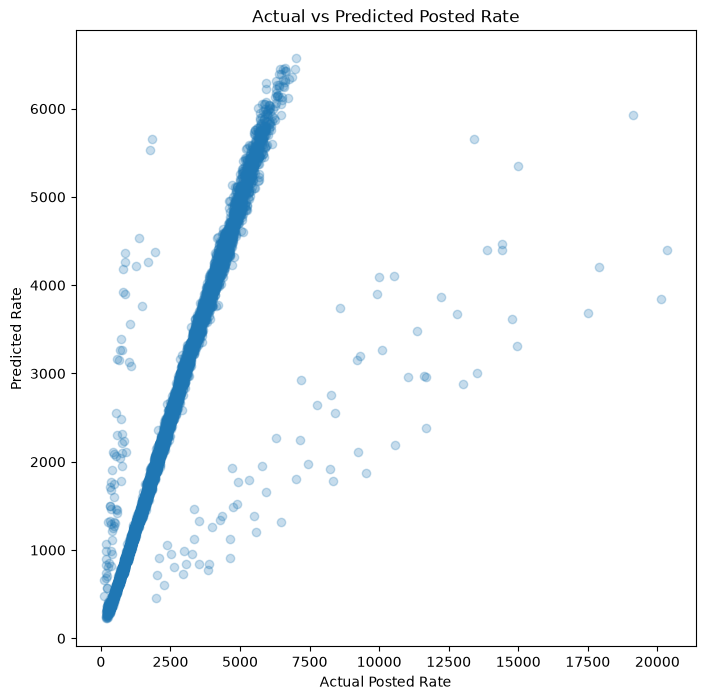

In [89]:
plt.figure(figsize=(8, 8))

plt.scatter(
    error_df["posted_rate"],
    error_df["predicted_rate"],
    alpha=0.25
)

plt.xlabel("Actual Posted Rate")
plt.ylabel("Predicted Rate")
plt.title("Actual vs Predicted Posted Rate")

plt.show()

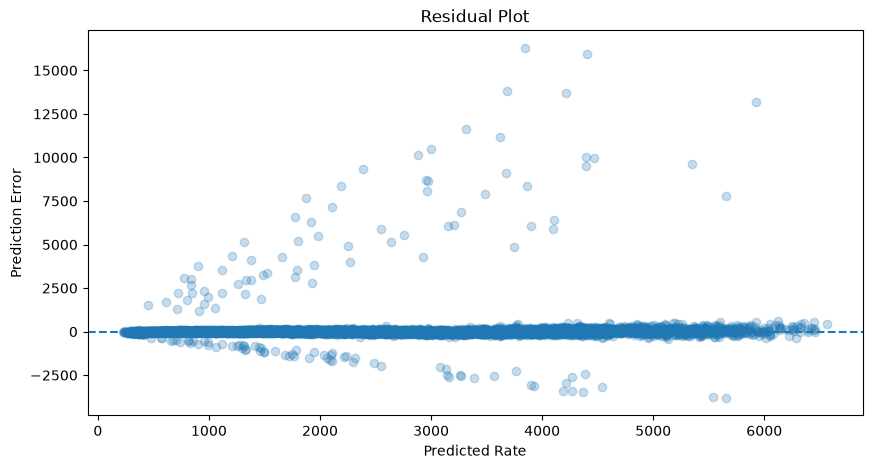

In [90]:
plt.figure(figsize=(10, 5))

plt.scatter(
    error_df["predicted_rate"],
    error_df["error"],
    alpha=0.25
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Rate")
plt.ylabel("Prediction Error")
plt.title("Residual Plot")

plt.show()

In [91]:
error_df["actual_bucket"] = pd.cut(
    error_df["posted_rate"],
    bins=[0, 1000, 2000, 3000, 5000, 10000, np.inf],
    labels=[
        "<1k",
        "1k-2k",
        "2k-3k",
        "3k-5k",
        "5k-10k",
        "10k+"
    ]
)

bucket_metrics = (
    error_df
    .groupby("actual_bucket", observed=False)
    .agg(
        loads=("posted_rate", "size"),
        mae=("absolute_error", "mean"),
        median_error=("absolute_error", "median")
    )
)

bucket_metrics

,loads,mae,median_error
actual_bucket,,,
<1k,1545,77.126825,20.972210
1k-2k,3077,43.888603,28.710994
2k-3k,2077,57.164241,42.590049
3k-5k,2316,95.935671,62.611753
5k-10k,484,391.434541,126.502459
10k+,24,10210.827368,9575.660632


In [92]:
high_rate = valid_data[
    valid_data["posted_rate"] >= 10000
].copy()

print("Number of high-rate loads:", len(high_rate))

high_rate[
    [
        "pickup",
        "delivery",
        "distance",
        "equipment",
        "weight",
        "market_index",
        "quote_signal",
        "posted_rate"
    ]
].sort_values(
    "posted_rate",
    ascending=False
)

Number of high-rate loads: 24


,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
40171,Montgomery,Fresno,2283.4,Dry Van,32447.0,0.98502,1.93645,20361.89
40096,Baltimore,Oklahoma City,1760.3,Reefer,29521.0,1.00464,2.28753,20132.37
47298,Boston,Bakersfield,2979.1,Reefer,30585.0,0.86501,2.09472,19110.30
46213,Columbia,Tucson,2023.4,Flatbed,34710.0,0.89822,2.06797,17893.17
43539,Milwaukee,Bakersfield,1893.0,Dry Van,30760.0,1.08079,2.22972,17514.11
47536,Los Angeles,Richmond,2782.4,Dry Van,25730.0,1.03410,2.39203,15003.55
40322,Montgomery,El Paso,1639.9,Dry Van,38363.0,0.96139,1.92501,14949.25
46516,Toledo,Albuquerque,1684.3,Reefer,31536.0,0.98632,2.05917,14784.38
44267,Albany,Albuquerque,2492.6,Dry Van,25513.0,1.05590,2.38846,14425.42
46366,Bakersfield,Columbia,2251.9,Dry Van,40729.0,0.94743,2.19163,14403.14


In [93]:
high_rate[
    [
        "distance",
        "weight",
        "market_index",
        "quote_signal",
        "posted_rate"
    ]
].describe()

,distance,weight,market_index,quote_signal,posted_rate
count,24.000000,24.000000,24.000000,24.000000,24.000000
mean,1903.816667,31597.083333,0.930843,2.057813,14003.431250
std,555.911591,7361.221555,0.094325,0.166242,3032.876568
min,1040.000000,16292.000000,0.746010,1.773160,10119.160000
25%,1473.400000,25675.750000,0.863842,1.933590,11662.595000
50%,1826.650000,31883.500000,0.952960,2.050490,13462.110000
75%,2226.400000,37017.500000,1.007270,2.178468,14962.825000
max,3183.800000,43567.000000,1.080790,2.392030,20361.890000


In [94]:
normal_rate = valid_data[
    valid_data["posted_rate"] < 10000
]

normal_rate[
    [
        "distance",
        "weight",
        "market_index",
        "quote_signal",
        "posted_rate"
    ]
].describe()

,distance,weight,market_index,quote_signal,posted_rate
count,9499.000000,9434.000000,9426.000000,9499.000000,9499.000000
mean,1133.300747,31178.056392,0.925844,2.068830,2363.114076
std,736.108250,9422.054714,0.082170,0.303347,1403.985012
min,70.000000,-45221.000000,0.676390,0.706200,104.380000
25%,541.750000,25932.000000,0.862675,1.898915,1240.425000
50%,943.300000,31562.000000,0.928075,2.065370,2040.470000
75%,1629.550000,37302.250000,0.992570,2.233120,3322.635000
max,3396.600000,47500.000000,1.141130,3.496590,9993.310000


In [95]:
high_rate_routes = (
    high_rate
    .groupby(["pickup", "delivery"])
    .agg(
        loads=("posted_rate", "size"),
        avg_rate=("posted_rate", "mean"),
        max_rate=("posted_rate", "max")
    )
    .sort_values("max_rate", ascending=False)
)

high_rate_routes

,,loads,avg_rate,max_rate
pickup,delivery,,,
Montgomery,Fresno,1,20361.89,20361.89
Baltimore,Oklahoma City,1,20132.37,20132.37
Boston,Bakersfield,1,19110.30,19110.30
Columbia,Tucson,1,17893.17,17893.17
Milwaukee,Bakersfield,1,17514.11,17514.11
Los Angeles,Richmond,1,15003.55,15003.55
Montgomery,El Paso,1,14949.25,14949.25
Toledo,Albuquerque,1,14784.38,14784.38
Albany,Albuquerque,1,14425.42,14425.42


In [96]:
high_rate.groupby("equipment")["posted_rate"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
equipment,,,,,
Dry Van,16,13515.068125,13223.405,10119.16,20361.89
Flatbed,2,14744.725000,14744.725,11596.28,17893.17
Reefer,6,15058.635000,14339.465,11052.72,20132.37


In [97]:
valid_data.groupby("equipment")["posted_rate"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
equipment,,,,,
Dry Van,5360,2281.166075,1952.440,123.32,20361.89
Flatbed,1770,2439.945136,2045.295,170.36,17893.17
Reefer,2393,2606.581659,2227.130,104.38,20132.37


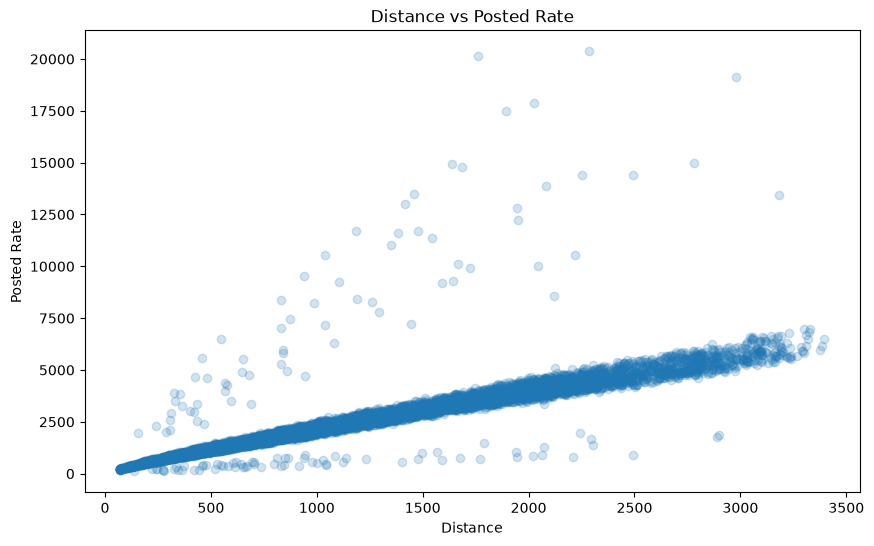

In [98]:
plt.figure(figsize=(10, 6))

plt.scatter(
    valid_data["distance"],
    valid_data["posted_rate"],
    alpha=0.2
)

plt.xlabel("Distance")
plt.ylabel("Posted Rate")
plt.title("Distance vs Posted Rate")

plt.show()

In [115]:
def create_features(df):
    df = df.copy()

    # -------------------------
    # Data quality
    # -------------------------
    # Convert invalid negative weights to NaN
    df["weight"] = df["weight"].where(
        df["weight"] >= 0,
        np.nan
    )

    # -------------------------
    # Date features
    # -------------------------
    df["date"] = pd.to_datetime(df["date"])

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day
    df["day_of_week"] = df["date"].dt.dayofweek

    # -------------------------
    # Route
    # -------------------------
    df["route"] = (
        df["pickup"].astype(str)
        + " -> "
        + df["delivery"].astype(str)
    )

    # -------------------------
    # Geographic features
    # -------------------------
    df["lat_diff"] = (
        df["delivery_lat"] - df["pickup_lat"]
    ).abs()

    df["lon_diff"] = (
        df["delivery_lon"] - df["pickup_lon"]
    ).abs()

    df["coord_distance"] = np.sqrt(
        (df["delivery_lat"] - df["pickup_lat"]) ** 2
        + (df["delivery_lon"] - df["pickup_lon"]) ** 2
    )

    # -------------------------
    # Distance
    # -------------------------
    df["distance_log"] = np.log1p(
        df["distance"]
    )

    # -------------------------
    # Weight
    # -------------------------
    df["weight_log"] = np.log1p(
        df["weight"]
    )

    return df

In [116]:
pd.set_option("display.max_columns", None)

high_rate[
    [
        "load_id",
        "pickup",
        "delivery",
        "pickup_lat",
        "pickup_lon",
        "delivery_lat",
        "delivery_lon",
        "distance",
        "equipment",
        "weight",
        "date",
        "market_index",
        "quote_signal",
        "posted_rate"
    ]
].sort_values(
    "posted_rate",
    ascending=False
)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
40171,TR-040172,Montgomery,Fresno,31.37602,-86.10743,33.07921,-119.79528,2283.4,Dry Van,32447.0,2025-09-11,0.98502,1.93645,20361.89
40096,TR-040097,Baltimore,Oklahoma City,38.16908,-72.74564,31.88294,-98.58097,1760.3,Reefer,29521.0,2025-09-11,1.00464,2.28753,20132.37
47298,TR-047299,Boston,Bakersfield,39.27463,-69.50000,33.28832,-116.67935,2979.1,Reefer,30585.0,2025-10-27,0.86501,2.09472,19110.30
46213,TR-046214,Columbia,Tucson,34.63570,-83.28506,30.92733,-113.23037,2023.4,Flatbed,34710.0,2025-10-20,0.89822,2.06797,17893.17
43539,TR-043540,Milwaukee,Bakersfield,39.62180,-88.48008,33.28832,-116.67935,1893.0,Dry Van,30760.0,2025-10-03,1.08079,2.22972,17514.11
47536,TR-047537,Los Angeles,Richmond,28.56624,-116.70249,38.09122,-76.78906,2782.4,Dry Van,25730.0,2025-10-29,1.03410,2.39203,15003.55
40322,TR-040323,Montgomery,El Paso,31.37602,-86.10743,33.31075,-110.31230,1639.9,Dry Van,38363.0,2025-09-12,0.96139,1.92501,14949.25
46516,TR-046517,Toledo,Albuquerque,41.97663,-84.45902,35.39918,-109.59792,1684.3,Reefer,31536.0,2025-10-22,0.98632,2.05917,14784.38
44267,TR-044268,Albany,Albuquerque,43.96975,-71.05842,35.39918,-109.59792,2492.6,Dry Van,25513.0,2025-10-08,1.05590,2.38846,14425.42
46366,TR-046367,Bakersfield,Columbia,33.28832,-116.67935,34.63570,-83.28506,2251.9,Dry Van,40729.0,2025-10-21,0.94743,2.19163,14403.14


In [117]:
train_fe = create_features(train_data)
valid_fe = create_features(valid_data)

In [118]:
df["distance_log"] = np.log1p(df["distance"])
df["weight_log"] = np.log1p(df["weight"])

NameError: name 'df' is not defined

In [119]:
print("Distance values <= -1:")
print(train_data.loc[train_data["distance"] <= -1, "distance"].value_counts())

print("\nWeight values <= -1:")
print(train_data.loc[train_data["weight"] <= -1, "weight"].value_counts())

Distance values <= -1:
Series([], Name: count, dtype: int64)

Weight values <= -1:
weight
-47500.0    13
-19389.0     2
-29838.0     2
-33033.0     2
-20003.0     1
            ..
-33494.0     1
-31453.0     1
-31268.0     1
-30378.0     1
-26020.0     1
Name: count, Length: 218, dtype: int64


In [120]:
print("Validation distance <= -1:")
print(valid_data.loc[valid_data["distance"] <= -1, "distance"].value_counts())

print("\nValidation weight <= -1:")
print(valid_data.loc[valid_data["weight"] <= -1, "weight"].value_counts())

Validation distance <= -1:
Series([], Name: count, dtype: int64)

Validation weight <= -1:
weight
-26959.0    2
-30839.0    1
-32397.0    1
-20180.0    1
-24397.0    1
-31560.0    1
-38535.0    1
-23983.0    1
-33699.0    1
-39242.0    1
-31212.0    1
-24471.0    1
-45221.0    1
-25982.0    1
-19750.0    1
-38068.0    1
-31935.0    1
-27674.0    1
-38340.0    1
-24867.0    1
-44395.0    1
-21194.0    1
-29209.0    1
-25616.0    1
-24646.0    1
-30943.0    1
-25804.0    1
-34903.0    1
-35282.0    1
-34863.0    1
-32569.0    1
-39325.0    1
-27654.0    1
-24412.0    1
-41272.0    1
-19060.0    1
-21645.0    1
-20894.0    1
-26628.0    1
-23606.0    1
-39085.0    1
-39628.0    1
-28773.0    1
-22295.0    1
-38106.0    1
-23865.0    1
-27695.0    1
-36959.0    1
-26380.0    1
-41218.0    1
-32790.0    1
-25999.0    1
-26533.0    1
-24142.0    1
-35617.0    1
-43951.0    1
-28144.0    1
-36262.0    1
Name: count, dtype: int64


In [121]:
print("Distance range:")
print(train_data["distance"].min(), train_data["distance"].max())

print("\nWeight range:")
print(train_data["weight"].min(), train_data["weight"].max())

Distance range:
70.0 3439.8

Weight range:
-47500.0 47500.0


In [122]:
print("Distance values <= -1:")
print(train_data.loc[train_data["distance"] <= -1, "distance"].value_counts())

Distance values <= -1:
Series([], Name: count, dtype: int64)


In [123]:
print("Weight values <= -1:")
print(train_data.loc[train_data["weight"] <= -1, "weight"].value_counts())

Weight values <= -1:
weight
-47500.0    13
-19389.0     2
-29838.0     2
-33033.0     2
-20003.0     1
            ..
-33494.0     1
-31453.0     1
-31268.0     1
-30378.0     1
-26020.0     1
Name: count, Length: 218, dtype: int64


In [124]:
print("Validation distance values <= -1:")
print(valid_data.loc[valid_data["distance"] <= -1, "distance"].value_counts())

print("\nValidation weight values <= -1:")
print(valid_data.loc[valid_data["weight"] <= -1, "weight"].value_counts())

Validation distance values <= -1:
Series([], Name: count, dtype: int64)

Validation weight values <= -1:
weight
-26959.0    2
-30839.0    1
-32397.0    1
-20180.0    1
-24397.0    1
-31560.0    1
-38535.0    1
-23983.0    1
-33699.0    1
-39242.0    1
-31212.0    1
-24471.0    1
-45221.0    1
-25982.0    1
-19750.0    1
-38068.0    1
-31935.0    1
-27674.0    1
-38340.0    1
-24867.0    1
-44395.0    1
-21194.0    1
-29209.0    1
-25616.0    1
-24646.0    1
-30943.0    1
-25804.0    1
-34903.0    1
-35282.0    1
-34863.0    1
-32569.0    1
-39325.0    1
-27654.0    1
-24412.0    1
-41272.0    1
-19060.0    1
-21645.0    1
-20894.0    1
-26628.0    1
-23606.0    1
-39085.0    1
-39628.0    1
-28773.0    1
-22295.0    1
-38106.0    1
-23865.0    1
-27695.0    1
-36959.0    1
-26380.0    1
-41218.0    1
-32790.0    1
-25999.0    1
-26533.0    1
-24142.0    1
-35617.0    1
-43951.0    1
-28144.0    1
-36262.0    1
Name: count, dtype: int64


In [125]:
print("Distance:")
print("Min:", train_data["distance"].min())
print("Max:", train_data["distance"].max())

print("\nWeight:")
print("Min:", train_data["weight"].min())
print("Max:", train_data["weight"].max())

Distance:
Min: 70.0
Max: 3439.8

Weight:
Min: -47500.0
Max: 47500.0


In [126]:
np.log1p(df["distance"])
np.log1p(df["weight"])

NameError: name 'df' is not defined

In [127]:
print("Training negative weights:",
      (train_data["weight"] < 0).sum())

print("Training zero weights:",
      (train_data["weight"] == 0).sum())

print("Training missing weights:",
      train_data["weight"].isna().sum())

print("\nValidation negative weights:",
      (valid_data["weight"] < 0).sum())

print("Validation zero weights:",
      (valid_data["weight"] == 0).sum())

print("Validation missing weights:",
      valid_data["weight"].isna().sum())

Training negative weights: 233
Training zero weights: 0
Training missing weights: 235

Validation negative weights: 59
Validation zero weights: 0
Validation missing weights: 65


In [128]:
print(train_data.loc[train_data["weight"] > 0, "weight"].describe())

count    38009.000000
mean     31378.083559
std       7978.851719
min       5000.000000
25%      25890.000000
50%      31467.000000
75%      37003.000000
max      47500.000000
Name: weight, dtype: float64


In [129]:
weight_log = log1p(positive_weight)

NameError: name 'log1p' is not defined

In [131]:
train_fe = create_features(train_data)
valid_fe = create_features(valid_data)

print("Training shape:", train_fe.shape)
print("Validation shape:", valid_fe.shape)

print("\nRemaining negative weights:")
print((train_fe["weight"] < 0).sum())

print("\nRemaining missing weights:")
print(train_fe["weight"].isna().sum())

Training shape: (38477, 25)
Validation shape: (9523, 25)

Remaining negative weights:
0

Remaining missing weights:
468


In [132]:
drop_columns = [
    "load_id",
    "posted_rate",
    "date",
    "rate_per_distance"
]

X_train_fe = train_fe.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

X_valid_fe = valid_fe.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

y_train_fe = train_fe["posted_rate"]
y_valid_fe = valid_fe["posted_rate"]

print("X_train:", X_train_fe.shape)
print("X_valid:", X_valid_fe.shape)

X_train: (38477, 21)
X_valid: (9523, 21)


In [133]:
categorical_features_fe = X_train_fe.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features_fe)

Categorical features:
['pickup', 'delivery', 'equipment', 'route']


In [134]:
for col in categorical_features_fe:
    X_train_fe[col] = X_train_fe[col].fillna("Missing")
    X_valid_fe[col] = X_valid_fe[col].fillna("Missing")

In [135]:
catboost_fe = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

In [136]:
catboost_fe.fit(
    X_train_fe,
    y_train_fe,
    cat_features=categorical_features_fe,
    eval_set=(X_valid_fe, y_valid_fe),
    early_stopping_rounds=100
)

0:	learn: 1417.6654406	test: 1467.0628217	best: 1467.0628217 (0)	total: 128ms	remaining: 2m 8s
100:	learn: 571.5204652	test: 633.7109954	best: 633.7109954 (100)	total: 17.3s	remaining: 2m 34s
200:	learn: 557.7302243	test: 632.0206787	best: 631.9773039 (154)	total: 32s	remaining: 2m 7s
300:	learn: 550.4336739	test: 631.9265302	best: 631.7795829 (274)	total: 47.3s	remaining: 1m 49s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 631.7795829
bestIteration = 274

Shrink model to first 275 iterations.


CatBoostRegressor(depth=8, eval_metric='RMSE', iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [137]:
fe_predictions = catboost_fe.predict(X_valid_fe)

fe_mae = mean_absolute_error(
    y_valid_fe,
    fe_predictions
)

fe_rmse = np.sqrt(
    mean_squared_error(
        y_valid_fe,
        fe_predictions
    )
)

fe_mape = np.mean(
    np.abs(
        (y_valid_fe - fe_predictions)
        / y_valid_fe
    )
) * 100

print("Feature-Engineered CatBoost MAE:", fe_mae)
print("Feature-Engineered CatBoost RMSE:", fe_rmse)
print("Feature-Engineered CatBoost MAPE:", fe_mape)

Feature-Engineered CatBoost MAE: 111.47601049206926
Feature-Engineered CatBoost RMSE: 631.7795874737928
Feature-Engineered CatBoost MAPE: 5.241842758440161


In [138]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "CatBoost",
        "CatBoost + Feature Engineering"
    ],
    "MAE": [
        mae,
        cb_mae,
        fe_mae
    ],
    "RMSE": [
        rmse,
        cb_rmse,
        fe_rmse
    ],
    "MAPE": [
        mape,
        cb_mape,
        fe_mape
    ]
})

comparison

,Model,MAE,RMSE,MAPE
0,Random Forest,152.543220,670.062903,6.675142
1,CatBoost,108.121127,630.827662,5.090160
2,CatBoost + Feature Engineering,111.476010,631.779587,5.241843


In [139]:
feature_importance = pd.DataFrame({
    "feature": X_train_cb.columns,
    "importance": catboost_model.get_feature_importance()
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance

,feature,importance
6,distance,84.668582
7,equipment,4.477936
9,market_index,1.796787
8,weight,1.673421
12,month,1.218348
10,quote_signal,1.015207
0,pickup,0.973542
1,delivery,0.831754
4,delivery_lat,0.693730
13,day,0.645549


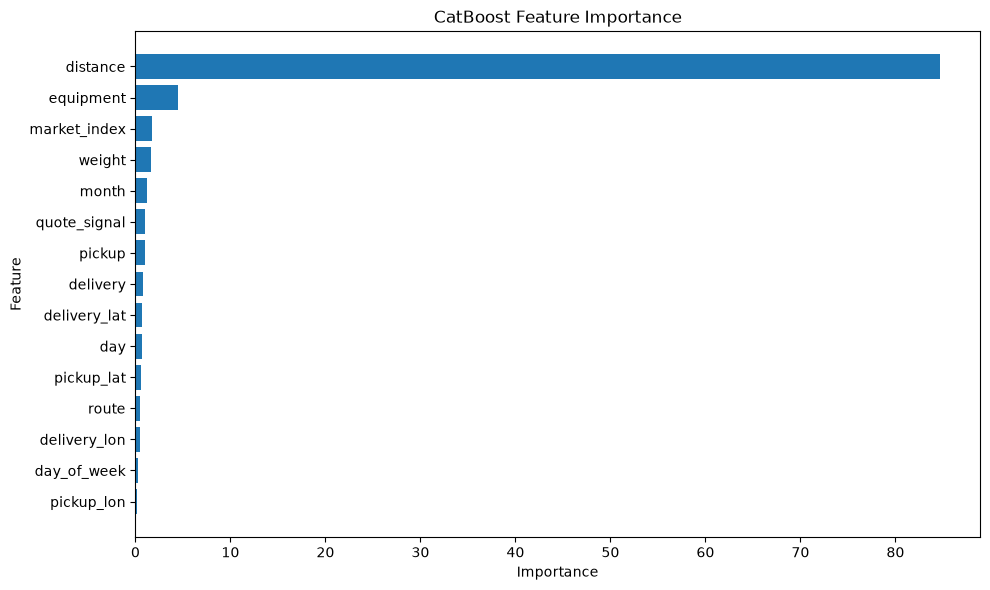

In [140]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("CatBoost Feature Importance")

plt.tight_layout()
plt.show()

In [141]:
print("Best iteration:", catboost_model.get_best_iteration())
print("Best validation RMSE:", catboost_model.get_best_score())

Best iteration: 291
Best validation RMSE: {'learn': {'RMSE': 550.5302597742328}, 'validation': {'RMSE': 630.8276571589561}}


In [143]:
catboost_d6 = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

catboost_d6.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features_cb,
    eval_set=(X_valid_cb, y_valid_cb),
    early_stopping_rounds=100
)

pred_d6 = catboost_d6.predict(X_valid_cb)

mae_d6 = mean_absolute_error(y_valid_cb, pred_d6)
rmse_d6 = np.sqrt(mean_squared_error(y_valid_cb, pred_d6))
mape_d6 = np.mean(
    np.abs((y_valid_cb - pred_d6) / y_valid_cb)
) * 100

print("Depth 6")
print("MAE:", mae_d6)
print("RMSE:", rmse_d6)
print("MAPE:", mape_d6)
print("Best iteration:", catboost_d6.get_best_iteration())

0:	learn: 1418.8570324	test: 1468.3731026	best: 1468.3731026 (0)	total: 84.3ms	remaining: 1m 24s
100:	learn: 579.7639887	test: 635.2109778	best: 635.2109778 (100)	total: 10.4s	remaining: 1m 32s
200:	learn: 573.4931934	test: 632.7251203	best: 632.7251203 (200)	total: 23s	remaining: 1m 31s
300:	learn: 568.7667580	test: 632.3670628	best: 632.3552055 (265)	total: 32.3s	remaining: 1m 15s
400:	learn: 564.7361913	test: 632.5018022	best: 632.3348751 (310)	total: 41s	remaining: 1m 1s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 632.3348751
bestIteration = 310

Shrink model to first 311 iterations.
Depth 6
MAE: 110.01201923011234
RMSE: 632.3348797790035
MAPE: 5.124437677841754
Best iteration: 310


In [144]:
catboost_d10 = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=10,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

catboost_d10.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features_cb,
    eval_set=(X_valid_cb, y_valid_cb),
    early_stopping_rounds=100
)

pred_d10 = catboost_d10.predict(X_valid_cb)

mae_d10 = mean_absolute_error(y_valid_cb, pred_d10)
rmse_d10 = np.sqrt(mean_squared_error(y_valid_cb, pred_d10))
mape_d10 = np.mean(
    np.abs((y_valid_cb - pred_d10) / y_valid_cb)
) * 100

print("Depth 10")
print("MAE:", mae_d10)
print("RMSE:", rmse_d10)
print("MAPE:", mape_d10)
print("Best iteration:", catboost_d10.get_best_iteration())

0:	learn: 1419.5288839	test: 1468.9253226	best: 1468.9253226 (0)	total: 201ms	remaining: 3m 20s
100:	learn: 565.3581447	test: 634.0678547	best: 634.0678547 (100)	total: 24.6s	remaining: 3m 38s
200:	learn: 550.6743813	test: 632.3765971	best: 632.3676258 (199)	total: 48.4s	remaining: 3m 12s
300:	learn: 541.8989077	test: 632.2074286	best: 632.1269601 (238)	total: 1m 15s	remaining: 2m 55s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 632.1269601
bestIteration = 238

Shrink model to first 239 iterations.
Depth 10
MAE: 110.97523298841949
RMSE: 632.1269647496681
MAPE: 5.159521068638329
Best iteration: 238


In [145]:
depth_comparison = pd.DataFrame({
    "Model": [
        "CatBoost depth 6",
        "CatBoost depth 8",
        "CatBoost depth 10"
    ],
    "MAE": [
        mae_d6,
        cb_mae,
        mae_d10
    ],
    "RMSE": [
        rmse_d6,
        cb_rmse,
        rmse_d10
    ],
    "MAPE": [
        mape_d6,
        mape,
        mape_d10
    ],
    "Best Iteration": [
        catboost_d6.get_best_iteration(),
        catboost_model.get_best_iteration(),
        catboost_d10.get_best_iteration()
    ]
})

depth_comparison

,Model,MAE,RMSE,MAPE,Best Iteration
0,CatBoost depth 6,110.012019,632.334880,5.124438,310
1,CatBoost depth 8,108.121127,630.827662,6.675142,291
2,CatBoost depth 10,110.975233,632.126965,5.159521,238


In [146]:
catboost_lr03 = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.03,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

catboost_lr03.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features_cb,
    eval_set=(X_valid_cb, y_valid_cb),
    early_stopping_rounds=100
)

pred_lr03 = catboost_lr03.predict(X_valid_cb)

mae_lr03 = mean_absolute_error(y_valid_cb, pred_lr03)
rmse_lr03 = np.sqrt(mean_squared_error(y_valid_cb, pred_lr03))
mape_lr03 = np.mean(
    np.abs((y_valid_cb - pred_lr03) / y_valid_cb)
) * 100

print("Learning Rate 0.03")
print("MAE:", mae_lr03)
print("RMSE:", rmse_lr03)
print("MAPE:", mape_lr03)
print("Best iteration:", catboost_lr03.get_best_iteration())

0:	learn: 1441.8937315	test: 1491.4584295	best: 1491.4584295 (0)	total: 133ms	remaining: 3m 19s
100:	learn: 587.7781197	test: 643.7227027	best: 643.7227027 (100)	total: 16.2s	remaining: 3m 44s
200:	learn: 571.1470861	test: 633.0899807	best: 633.0899807 (200)	total: 31.9s	remaining: 3m 25s
300:	learn: 565.1917415	test: 632.1874809	best: 632.1874809 (300)	total: 47.7s	remaining: 3m 9s
400:	learn: 560.6084220	test: 632.1417075	best: 632.1276866 (395)	total: 1m 1s	remaining: 2m 48s
500:	learn: 557.5840163	test: 632.1025398	best: 632.0946204 (499)	total: 1m 14s	remaining: 2m 28s
600:	learn: 553.4930947	test: 632.3014117	best: 632.0771349 (515)	total: 1m 41s	remaining: 2m 31s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 632.0771349
bestIteration = 515

Shrink model to first 516 iterations.
Learning Rate 0.03
MAE: 107.6334362761845
RMSE: 632.0771396260969
MAPE: 5.0320024553535045
Best iteration: 515


In [147]:
catboost_lr10 = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.10,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

catboost_lr10.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features_cb,
    eval_set=(X_valid_cb, y_valid_cb),
    early_stopping_rounds=100
)

pred_lr10 = catboost_lr10.predict(X_valid_cb)

mae_lr10 = mean_absolute_error(y_valid_cb, pred_lr10)
rmse_lr10 = np.sqrt(mean_squared_error(y_valid_cb, pred_lr10))
mape_lr10 = np.mean(
    np.abs((y_valid_cb - pred_lr10) / y_valid_cb)
) * 100

print("Learning Rate 0.10")
print("MAE:", mae_lr10)
print("RMSE:", rmse_lr10)
print("MAPE:", mape_lr10)
print("Best iteration:", catboost_lr10.get_best_iteration())

0:	learn: 1362.1351293	test: 1411.3295502	best: 1411.3295502 (0)	total: 129ms	remaining: 2m 8s
100:	learn: 564.3389329	test: 632.9793822	best: 632.8768318 (70)	total: 19.2s	remaining: 2m 51s
200:	learn: 547.8384053	test: 633.3336274	best: 632.6275477 (144)	total: 32.5s	remaining: 2m 9s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 632.6275477
bestIteration = 144

Shrink model to first 145 iterations.
Learning Rate 0.10
MAE: 113.10171679176946
RMSE: 632.6275523966374
MAPE: 5.359419007768519
Best iteration: 144


In [148]:
lr_comparison = pd.DataFrame({
    "Model": [
        "LR 0.03",
        "LR 0.05",
        "LR 0.10"
    ],
    "MAE": [
        mae_lr03,
        cb_mae,
        mae_lr10
    ],
    "RMSE": [
        rmse_lr03,
        cb_rmse,
        rmse_lr10
    ],
    "MAPE": [
        mape_lr03,
        mape,
        mape_lr10
    ],
    "Best Iteration": [
        catboost_lr03.get_best_iteration(),
        catboost_model.get_best_iteration(),
        catboost_lr10.get_best_iteration()
    ]
})

lr_comparison

,Model,MAE,RMSE,MAPE,Best Iteration
0,LR 0.03,107.633436,632.077140,5.032002,515
1,LR 0.05,108.121127,630.827662,6.675142,291
2,LR 0.10,113.101717,632.627552,5.359419,144


In [149]:
final_mae = mean_absolute_error(
    y_valid_cb,
    cb_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_valid_cb,
        cb_predictions
    )
)

final_mape = np.mean(
    np.abs(
        (y_valid_cb - cb_predictions)
        / y_valid_cb
    )
) * 100

print("Final validation MAE:", final_mae)
print("Final validation RMSE:", final_rmse)
print("Final validation MAPE:", final_mape)

Final validation MAE: 108.1211270483614
Final validation RMSE: 630.8276618739579
Final validation MAPE: 5.090159977039365


In [150]:
full_train = train_df.copy()
final_validation = validation_df.copy()

target = "posted_rate"

drop_columns = [
    "load_id",
    "posted_rate",
    "rate_per_distance"
]

X_full = full_train.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

y_full = full_train[target].copy()

X_test = final_validation.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

In [151]:
X_full = X_full.drop(
    columns=["date"],
    errors="ignore"
)

X_test = X_test.drop(
    columns=["date"],
    errors="ignore"
)

In [152]:
categorical_features_final = X_full.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features_final)

Categorical features:
['pickup', 'delivery', 'equipment', 'route']


In [1]:
for col in categorical_features_final:
    X_full[col] = X_full[col].fillna("Missing")
    X_test[col] = X_test[col].fillna("Missing")

NameError: name 'categorical_features_final' is not defined

In [154]:
final_model = CatBoostRegressor(
    iterations=291,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

In [155]:
# Original columns from the raw development data
original_features = [
    "pickup",
    "delivery",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "equipment",
    "weight",
    "date",
    "market_index",
    "quote_signal"
]

X_full = train_df[original_features].copy()
y_full = train_df["posted_rate"].copy()

X_test = validation_df[original_features].copy()

print("X_full shape:", X_full.shape)
print("X_test shape:", X_test.shape)

X_full shape: (48000, 12)
X_test shape: (12000, 12)


In [156]:
X_full = X_full.drop(columns=["date"])
X_test = X_test.drop(columns=["date"])

In [157]:
categorical_features_final = X_full.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features_final)

Categorical features:
['pickup', 'delivery', 'equipment']


In [158]:
for col in categorical_features_final:
    X_full[col] = X_full[col].fillna("Missing")
    X_test[col] = X_test[col].fillna("Missing")

In [159]:
final_model = CatBoostRegressor(
    iterations=291,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

final_model.fit(
    X_full,
    y_full,
    cat_features=categorical_features_final
)

0:	learn: 1427.3304512	total: 108ms	remaining: 31.3s
100:	learn: 586.8054603	total: 11.8s	remaining: 22.2s
200:	learn: 580.0785484	total: 22.2s	remaining: 9.96s
290:	learn: 574.4817375	total: 30.4s	remaining: 0us


CatBoostRegressor(depth=8, iterations=291, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [160]:
final_predictions = final_model.predict(X_test)

print("Number of predictions:", len(final_predictions))
print("\nFirst 10 predictions:")
print(final_predictions[:10])

Number of predictions: 12000

First 10 predictions:
[ 852.4191978  4903.76989504 5257.59208644 4041.07960022 1852.86840614
 4454.09882083 5254.09309008 2822.83766748 1071.0284232  1141.40739994]


In [2]:
prediction_df = pd.DataFrame({
    "load_id": validation_df["load_id"],
    "predicted_rate": final_predictions
})

print(prediction_df.head())
print("\nShape:", prediction_df.shape)
print("\nColumns:", prediction_df.columns.tolist())

NameError: name 'pd' is not defined

In [3]:
import pandas as pd
import numpy as np
from catboost import CatBoostRegressor

# Load raw datasets
train_df = pd.read_csv("data/train-test.csv")
validation_df = pd.read_csv("data/validation.csv")

# Convert dates
train_df["date"] = pd.to_datetime(train_df["date"])
validation_df["date"] = pd.to_datetime(validation_df["date"])

# Create the SAME features used by our validated CatBoost model
for df in [train_df, validation_df]:
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day
    df["day_of_week"] = df["date"].dt.dayofweek

    df["route"] = (
        df["pickup"].astype(str)
        + " -> "
        + df["delivery"].astype(str)
    )

# Features used by the validated CatBoost
feature_columns = [
    "pickup",
    "delivery",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "year",
    "month",
    "day",
    "day_of_week",
    "route"
]

X_full = train_df[feature_columns].copy()
y_full = train_df["posted_rate"].copy()

X_test = validation_df[feature_columns].copy()

# Categorical features
categorical_features = [
    "pickup",
    "delivery",
    "equipment",
    "route"
]

# Handle missing categorical values
for col in categorical_features:
    X_full[col] = X_full[col].fillna("Missing")
    X_test[col] = X_test[col].fillna("Missing")

print("X_full shape:", X_full.shape)
print("X_test shape:", X_test.shape)
print("Categorical features:", categorical_features)

# Final model
final_model = CatBoostRegressor(
    iterations=291,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

# Train on all 48,000 labeled rows
final_model.fit(
    X_full,
    y_full,
    cat_features=categorical_features
)

# Predict 12,000 validation rows
final_predictions = final_model.predict(X_test)

print("\nNumber of predictions:", len(final_predictions))
print("\nFirst 10 predictions:")
print(final_predictions[:10])

X_full shape: (48000, 16)
X_test shape: (12000, 16)
Categorical features: ['pickup', 'delivery', 'equipment', 'route']
0:	learn: 1428.6608665	total: 413ms	remaining: 1m 59s
100:	learn: 586.0200832	total: 15.5s	remaining: 29.2s
200:	learn: 574.5238659	total: 29.1s	remaining: 13s
290:	learn: 566.2972772	total: 39.5s	remaining: 0us

Number of predictions: 12000

First 10 predictions:
[ 858.74711296 5038.90580327 5225.23460318 4083.32560067 1872.34199185
 4384.43913074 5286.1769511  2836.50272431 1128.46704071 1111.01379665]


In [4]:
prediction_df = pd.DataFrame({
    "load_id": validation_df["load_id"].values,
    "predicted_rate": final_predictions
})

print(prediction_df.head())
print("\nShape:", prediction_df.shape)
print("\nColumns:", prediction_df.columns.tolist())

     load_id  predicted_rate
0  TE-000001      858.747113
1  TE-000002     5038.905803
2  TE-000003     5225.234603
3  TE-000004     4083.325601
4  TE-000005     1872.341992

Shape: (12000, 2)

Columns: ['load_id', 'predicted_rate']


In [5]:
prediction_df.to_csv(
    "validation-predictions.csv",
    index=False
)

print("CSV saved successfully!")

CSV saved successfully!


In [6]:
check_df = pd.read_csv("validation-predictions.csv")

print("Shape:", check_df.shape)
print("\nColumns:", check_df.columns.tolist())
print("\nMissing values:")
print(check_df.isna().sum())
print("\nDuplicate load IDs:", check_df["load_id"].duplicated().sum())
print("\nFirst 5 rows:")
print(check_df.head())

Shape: (12000, 2)

Columns: ['load_id', 'predicted_rate']

Missing values:
load_id           0
predicted_rate    0
dtype: int64

Duplicate load IDs: 0

First 5 rows:
     load_id  predicted_rate
0  TE-000001      858.747113
1  TE-000002     5038.905803
2  TE-000003     5225.234603
3  TE-000004     4083.325601
4  TE-000005     1872.341992


In [7]:
december_df = pd.read_csv("december-chart-inputs.csv")

print("Shape:", december_df.shape)
print("\nColumns:")
print(december_df.columns.tolist())

print("\nFirst 5 rows:")
print(december_df.head())

print("\nData types:")
print(december_df.dtypes)

Shape: (31, 7)

Columns:
['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']

First 5 rows:
      pickup    delivery  distance equipment  weight        date  \
0  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01   
1  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02   
2  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03   
3  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04   
4  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05   

   predicted_rate  
0             NaN  
1             NaN  
2             NaN  
3             NaN  
4             NaN  

Data types:
pickup             object
delivery           object
distance            int64
equipment          object
weight              int64
date               object
predicted_rate    float64
dtype: object


In [8]:
december_df = pd.read_csv("december-chart-inputs.csv")

print(december_df)

       pickup    delivery  distance equipment  weight        date  \
0   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01   
1   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02   
2   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03   
3   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04   
4   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05   
5   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-06   
6   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-07   
7   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-08   
8   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-09   
9   Lexington  Fort Wayne       360   Dry Van   32000  2025-12-10   
10  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-11   
11  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-12   
12  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-13   
13  Lexington  Fort Wayne       36

In [9]:
train_df[
    (train_df["pickup"] == "Lexington") &
    (train_df["delivery"] == "Fort Wayne")
][
    [
        "pickup",
        "delivery",
        "pickup_lat",
        "pickup_lon",
        "delivery_lat",
        "delivery_lon",
        "distance",
        "equipment",
        "weight",
        "market_index",
        "quote_signal"
    ]
].head(20)

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,quote_signal
654,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,358.3,Dry Van,22567.0,0.79554,2.11108
886,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,383.2,Reefer,36531.0,0.79837,2.43088
1571,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,358.2,Dry Van,31556.0,0.87356,2.18657
2821,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,362.1,Dry Van,27842.0,0.84023,2.14650
3913,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,357.5,Dry Van,37102.0,0.92241,2.26175
6788,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,376.8,Dry Van,41021.0,1.04296,2.30284
8369,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,355.1,Dry Van,27601.0,0.95940,2.21525
10557,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,359.9,Dry Van,24178.0,1.01780,2.19709
11817,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,367.6,Dry Van,16195.0,0.99336,2.21027
12207,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,363.1,Dry Van,27600.0,1.14812,2.24940


In [10]:
# Load December inputs
december_df = pd.read_csv("december-chart-inputs.csv")

december_df["date"] = pd.to_datetime(december_df["date"])

# Historical Lexington -> Fort Wayne Dry Van data
route_history = train_df[
    (train_df["pickup"] == "Lexington") &
    (train_df["delivery"] == "Fort Wayne") &
    (train_df["equipment"] == "Dry Van")
].copy()

print("Historical route observations:", len(route_history))

print("\nMedian market index:",
      route_history["market_index"].median())

print("Median quote signal:",
      route_history["quote_signal"].median())

Historical route observations: 21

Median market index: 1.0178
Median quote signal: 2.11108


In [11]:
december_model_input = pd.DataFrame({
    "pickup": december_df["pickup"],
    "delivery": december_df["delivery"],
    "pickup_lat": 36.99152,
    "pickup_lon": -84.99876,
    "delivery_lat": 41.31561,
    "delivery_lon": -85.36206,
    "distance": december_df["distance"],
    "equipment": december_df["equipment"],
    "weight": december_df["weight"],
    "market_index": route_history["market_index"].median(),
    "quote_signal": route_history["quote_signal"].median(),
    "year": december_df["date"].dt.year,
    "month": december_df["date"].dt.month,
    "day": december_df["date"].dt.day,
    "day_of_week": december_df["date"].dt.dayofweek,
    "route": (
        december_df["pickup"].astype(str)
        + " -> "
        + december_df["delivery"].astype(str)
    )
})

# Categorical missing handling
for col in categorical_features:
    december_model_input[col] = (
        december_model_input[col].fillna("Missing")
    )

print(december_model_input.shape)
print(december_model_input.head())

(31, 16)
      pickup    delivery  pickup_lat  pickup_lon  delivery_lat  delivery_lon  \
0  Lexington  Fort Wayne    36.99152   -84.99876      41.31561     -85.36206   
1  Lexington  Fort Wayne    36.99152   -84.99876      41.31561     -85.36206   
2  Lexington  Fort Wayne    36.99152   -84.99876      41.31561     -85.36206   
3  Lexington  Fort Wayne    36.99152   -84.99876      41.31561     -85.36206   
4  Lexington  Fort Wayne    36.99152   -84.99876      41.31561     -85.36206   

   distance equipment  weight  market_index  quote_signal  year  month  day  \
0       360   Dry Van   32000        1.0178       2.11108  2025     12    1   
1       360   Dry Van   32000        1.0178       2.11108  2025     12    2   
2       360   Dry Van   32000        1.0178       2.11108  2025     12    3   
3       360   Dry Van   32000        1.0178       2.11108  2025     12    4   
4       360   Dry Van   32000        1.0178       2.11108  2025     12    5   

   day_of_week                    r

In [12]:
december_predictions = final_model.predict(
    december_model_input
)

print("Number of December predictions:",
      len(december_predictions))

print("\nPredictions:")
print(december_predictions)

Number of December predictions: 31

Predictions:
[807.63291387 813.63709564 820.10777817 818.67074734 814.16711845
 811.51208579 816.0608138  814.49100247 818.17580271 823.2225938
 825.84275897 821.03242088 817.86894639 822.12093651 823.18377048
 827.7834081  828.99349459 828.59756759 823.83602246 819.26708714
 821.54069206 825.01717208 829.81622719 831.4697237  829.51435719
 827.49732634 812.81694751 821.50455846 825.82632091 828.33462824
 829.55688583]


In [13]:
december_output = december_df.copy()

december_output["predicted_rate"] = december_predictions

print(december_output)

       pickup    delivery  distance equipment  weight       date  \
0   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-01   
1   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-02   
2   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-03   
3   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-04   
4   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-05   
5   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-06   
6   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-07   
7   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-08   
8   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-09   
9   Lexington  Fort Wayne       360   Dry Van   32000 2025-12-10   
10  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-11   
11  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-12   
12  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-13   
13  Lexington  Fort Wayne       360   Dry Van   

In [14]:
print(december_output.columns.tolist())
print(december_output.shape)

['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
(31, 7)


In [15]:
december_output.to_csv(
    "december_chart_inputs_completed.csv",
    index=False
)

print("December predictions saved!")

December predictions saved!


In [16]:
december_output.to_csv(
    "december_chart_inputs_completed.csv",
    index=False
)

print("Saved:", "december_chart_inputs_completed.csv")
print("Shape:", december_output.shape)
print(december_output.head())

Saved: december_chart_inputs_completed.csv
Shape: (31, 7)
      pickup    delivery  distance equipment  weight       date  \
0  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-01   
1  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-02   
2  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-03   
3  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-04   
4  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-05   

   predicted_rate  
0      807.632914  
1      813.637096  
2      820.107778  
3      818.670747  
4      814.167118  
